# K-Means Clustering from Scratch on the Iris Dataset

This notebook implements the K-Means algorithm from scratch using NumPy, with petal length and sepal width as the two features. The elbow method is used to choose the number of clusters.

In [1]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import random
import collections
from sklearn.datasets import load_iris
import pandas as pd

## Data

The two features are petal length and sepal width, taken from the Iris dataset. The class labels are not used for clustering.

In [2]:
# loading the dataset and creating the points
iris = load_iris(as_frame=True)
df = iris.frame

# petal length and sepal width as the two features
data = df[['petal length (cm)', 'sepal width (cm)']]

data.head()

points=data.values.tolist()
points=np.array(points)

## Helper Functions

K-Means is built from four small pieces: finding the nearest centroid for a point, recomputing the centroids, choosing the initial centroids, and measuring the sum of squared errors (SSE).

In [3]:
# returns the index of the nearest centroid
def closest_centroid(point,centroids):
  distances=[]
  for centroid in centroids:
    distance=np.linalg.norm(point-centroid)
    distances.append(distance)
  return np.argmin(distances)

In [4]:
# new centroid = mean of the points in each cluster
def update_centroids(clusters):
  centroids=[]
  for cluster_id in clusters:
    centroid=np.mean(clusters[cluster_id],axis=0)
    centroids.append(centroid)
  return np.array(centroids)

In [5]:
# picks p distinct points from the global points array
def initialize_centroids(seed,p):
  np.random.seed(seed)
  indices=np.random.choice(len(points),size=p,replace=False)
  centroids=points[indices]
  return np.array(centroids)

In [6]:
# squared distance of every point to its own centroid
def calculate_sse(centroids,clusters,k):
  sse=0
  for i in range(k):
    for point in clusters[i]:
      distance=np.linalg.norm(point-centroids[i])
      sse+=distance**2
  return sse

## The K-Means Loop

Each point is assigned to its nearest centroid, and the centroids are then recomputed as the mean of their points. This repeats until the centroids stop moving. The implementation does not handle empty clusters, which did not occur with the seed used here.

In [7]:
# stop when the centroids no longer move
def kmeans(p,points,centroids):
  while True:
    clusters={i:[] for i in range(p)}
    for point in points:
      cluster_index=closest_centroid(point,centroids)
      clusters[cluster_index].append(point)
    old_centroids=centroids.copy()
    centroids=update_centroids(clusters)
    if np.allclose(old_centroids,centroids):
      break
  return centroids,clusters

## Choosing the Number of Clusters

K-Means is run for 1 to 4 clusters with a fixed seed of 42, and the SSE is plotted against the number of clusters.

Cluster counts:  [1, 2, 3, 4]
SSE values:  [np.float64(492.63233333333324), np.float64(86.31064765300059), np.float64(40.989161990561975), np.float64(27.48469523809523)]


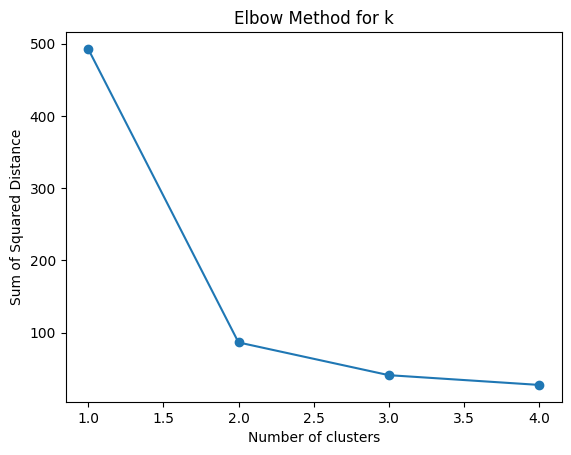

In [8]:

cluster_counts=[]
sse_values=[]
for k in range(1,5):
  initial_centroids=initialize_centroids(42,k)
  final_centroids,final_clusters=kmeans(k,points,initial_centroids)
  sse=calculate_sse(final_centroids,final_clusters,k)
  cluster_counts.append(k)
  sse_values.append(sse)
print("Cluster counts: ",cluster_counts)
print("SSE values: ",sse_values)

#plot
plt.plot(cluster_counts,sse_values,marker="o")
plt.title("Elbow Method for k")
plt.xlabel("Number of clusters")
plt.ylabel("Sum of Squared Distance")
plt.show()

The SSE falls sharply from 492.6 at k=1 to 86.3 at k=2, and then by much less, to 41.0 at k=3 and 27.5 at k=4. The curve bends at k=2, so k=2 is used below. A choice of k=3 would also be reasonable, since the dataset has three species. The bend is not sharp enough to decide from the plot alone.

## Clustering with k = 2

The data is clustered with the chosen k and plotted with the centroids marked.

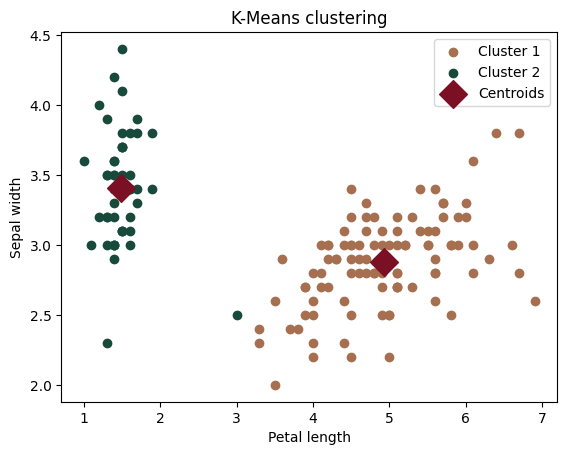

In [9]:
# one colour per cluster, centroids drawn as diamonds
best_k=2
initial_centroids=initialize_centroids(42,best_k)
final_centroids,final_clusters=kmeans(best_k,points,initial_centroids)
cluster_1=np.array(final_clusters[0])
cluster_2=np.array(final_clusters[1])

#plot
plt.scatter(cluster_1[:,0],cluster_1[:,1],label="Cluster 1",color="#A66F4F")
plt.scatter(cluster_2[:,0],cluster_2[:,1],label="Cluster 2",color="#174A3A")
plt.scatter(final_centroids[:,0],final_centroids[:,1],marker="D",s=200,label="Centroids",color="#7B1025")
plt.title("K-Means clustering")
plt.xlabel("Petal length")
plt.ylabel("Sepal width")
plt.legend()
plt.show()

K-Means separates a compact group in the upper left, with short petals and wide sepals, from the rest of the data. That group holds about a third of the points. Species labels were not used, but this group corresponds to setosa, which has much shorter petals. Versicolor and virginica overlap in these two features and end up in the same cluster.

## Conclusions

With k=2, K-Means recovers the setosa group cleanly but cannot separate versicolor from virginica on these two features. Increasing k to 3 lowers the SSE further, and the elbow plot alone does not rule it out.

K-Means also depends on the initial centroids and can settle in a poor local minimum. The seed was fixed at 42 for reproducibility, and other seeds would be worth trying.